# Atelier AI - Behavioral EDA

Explore observed purchase behavior to motivate retrieval sources, feature families and evaluation segments. Each section follows **question → calculation → chart → observation → hypothesis → modelling consequence**.

All behavioral calculations use **[2018-09-20, 2020-09-02)**. Source purchase rows are retained; they do not identify orders. Product classifications describe the acquired metadata snapshot. No recommendation performance is measured here.

The calendar is shared with [data foundation](01_data_foundation.ipynb). The exact methods and limits are recorded in the [evaluation strategy](../docs/evaluation.md).

## 1. Sources and analytical contract

The prepared Parquet tables preserve string identifiers and transaction repetitions. SQL aggregates use the complete announced interval; no future purchase selects customers. Only plotted individual scatter points would require sampling, which is unnecessary for these aggregated views.

Metadata joins must preserve transaction counts. `Unknown` remains a source category. The metadata snapshot does not establish historical stock or account creation dates.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
import atelier_ai
from atelier_ai.temporal_protocol import load_protocol
from atelier_ai.notebook_tools import show_figure

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
protocol = load_protocol(PROJECT_ROOT)

from atelier_ai.preparation import prepare_sources, open_prepared
prepare_sources(PROJECT_ROOT)
connection = open_prepared(PROJECT_ROOT)
EDA_END_EXCLUSIVE = protocol['validation_start']
connection.sql("SELECT * FROM transactions WHERE t_dat < DATE '" + EDA_END_EXCLUSIVE.strftime('%Y-%m-%d') + "'").create_view('eda')
connection.sql('SELECT t.*, a.product_group_name, a.product_type_name, a.colour_group_name FROM eda t LEFT JOIN articles a USING(article_id)').create_view('eda_joined')

def query(sql):
    return connection.sql(sql).df()

scope = query('SELECT count(*) transaction_rows, count(DISTINCT customer_id) customers, count(DISTINCT article_id) articles, min(t_dat) first_date, max(t_dat) last_date FROM eda')
assert int(scope.loc[0, 'transaction_rows']) == 31_028_115
assert int(query('SELECT count(*) n FROM eda_joined').loc[0, 'n']) == 31_028_115
assert int(query('SELECT count(*) n FROM eda_joined WHERE product_group_name IS NULL OR product_type_name IS NULL OR colour_group_name IS NULL').loc[0, 'n']) == 0
display(scope)

,transaction_rows,customers,articles,first_date,last_date
0,31028115,1345600,101945,2018-09-20,2020-09-01


## 2. Daily activity

**Question.** How much observed purchase activity occurs on each date?

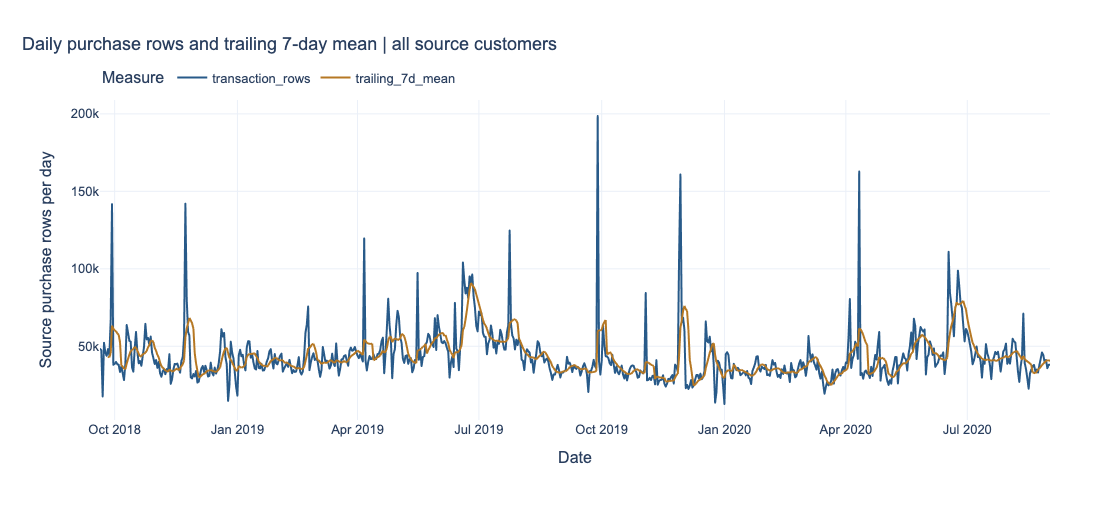

count       713.000000
mean      43517.692847
std       17261.494695
min       12760.000000
25%       33981.000000
50%       39561.000000
75%       47744.000000
max      198622.000000
Name: transaction_rows, dtype: float64

In [2]:
daily = query('SELECT t_dat, count(*) transaction_rows FROM eda GROUP BY t_dat ORDER BY t_dat')
assert len(daily) == 713 and daily['transaction_rows'].sum() == 31_028_115
daily['trailing_7d_mean'] = daily['transaction_rows'].rolling(7, min_periods=7).mean()
fig = px.line(daily, x='t_dat', y=['transaction_rows', 'trailing_7d_mean'],
    labels={'t_dat':'Date', 'value':'Source purchase rows per day', 'variable':'Measure'},
    title='Daily purchase rows and trailing 7-day mean | all source customers')
show_figure(fig, PROJECT_ROOT, 'eda_daily')
display(daily['transaction_rows'].describe())

**Interpretation and hypothesis.** Daily rows measure activity, not conversion or demand conditional on exposure. The trailing mean smooths short fluctuations and is undefined for the first six dates. Recent popularity windows are plausible signals; their predictive usefulness must be tested on validation.

## 3. Weekday activity

**Question.** Do weekday comparisons depend on the summary statistic?

,weekday_number,size,mean,median,weekday
0,0,102,38765.392157,36696.0,Monday
1,1,102,40228.392157,37883.5,Tuesday
2,2,101,46945.000000,42585.0,Wednesday
3,3,102,46462.500000,43108.0,Thursday
4,4,102,45422.392157,41437.5,Friday
5,5,102,48327.754902,41839.5,Saturday
6,6,102,38506.019608,35055.0,Sunday


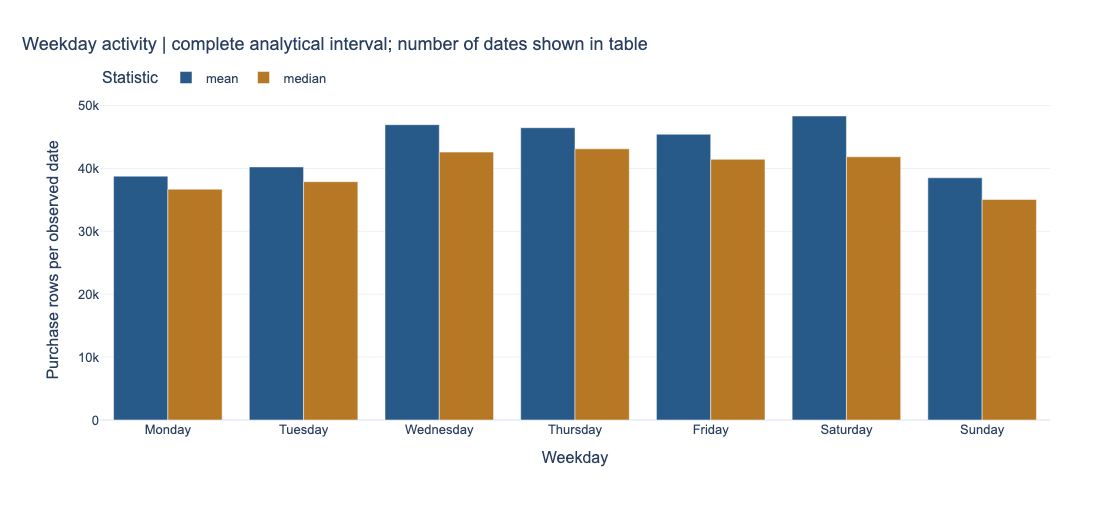

In [3]:
daily['weekday_number'] = daily['t_dat'].dt.dayofweek
weekday = daily.groupby('weekday_number')['transaction_rows'].agg(['size','mean','median']).reset_index()
weekday['weekday'] = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
display(weekday)
fig = px.bar(weekday, x='weekday', y=['mean','median'], barmode='group',
    labels={'value':'Purchase rows per observed date','variable':'Statistic','weekday':'Weekday'},
    title='Weekday activity | complete analytical interval; number of dates shown in table')
show_figure(fig, PROJECT_ROOT, 'eda_weekday')

**Interpretation and hypothesis.** Means and medians answer different questions. Their difference can reflect unusually busy dates. A calendar feature describes prediction context; weekday patterns alone do not establish a causal effect.

## 4. Weekly category composition

**Question.** How do broad product-group shares change across weeks?

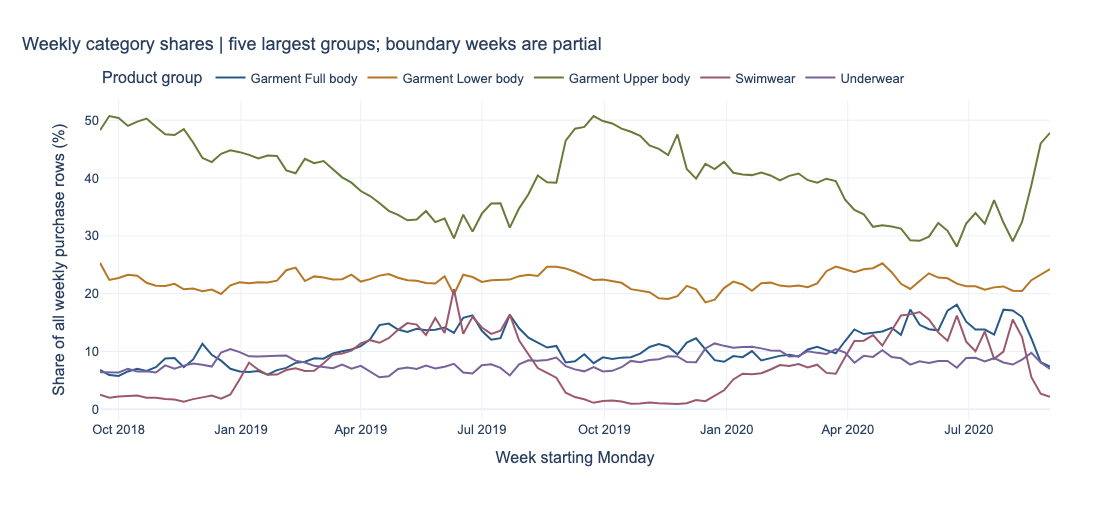

,week,product_group_name,transaction_rows,share_pct
1537,2020-08-24,Shoes,5074,1.770875
1538,2020-08-24,Socks & Tights,7319,2.554402
1539,2020-08-24,Stationery,4,0.001396
1540,2020-08-24,Swimwear,7750,2.704825
1541,2020-08-24,Underwear,23157,8.082017
1542,2020-08-24,Underwear/nightwear,2,0.000698
1543,2020-08-24,Unknown,3846,1.342291
1544,2020-08-31,Accessories,3505,4.601670
1545,2020-08-31,Bags,45,0.059080
1546,2020-08-31,Garment Full body,5607,7.361359


In [4]:
weekly_groups = query("SELECT date_trunc('week',t_dat) AS week, product_group_name, count(*) transaction_rows FROM eda_joined GROUP BY ALL ORDER BY week,product_group_name")
weekly_totals = weekly_groups.groupby('week')['transaction_rows'].sum()
weekly_groups['share_pct'] = 100 * weekly_groups['transaction_rows'] / weekly_groups['week'].map(weekly_totals)
assert np.allclose(weekly_groups.groupby('week')['share_pct'].sum(),100)
leading_groups = weekly_groups.groupby('product_group_name')['transaction_rows'].sum().nlargest(5).index
fig = px.line(weekly_groups.loc[weekly_groups['product_group_name'].isin(leading_groups)],
    x='week', y='share_pct', color='product_group_name',
    labels={'week':'Week starting Monday','share_pct':'Share of all weekly purchase rows (%)','product_group_name':'Product group'},
    title='Weekly category shares | five largest groups; boundary weeks are partial')
show_figure(fig, PROJECT_ROOT, 'eda_weekly_category_shares')
display(weekly_groups.tail(19))

**Interpretation and hypothesis.** Every share uses all eligible rows in that week as its denominator; the five plotted groups need not sum to 100%. The first and last weeks are partial. Composition changes motivate recent category signals, without proving future seasonality.

## 5. Category-by-week matrix

**Question.** Are temporal composition patterns shared across categories?

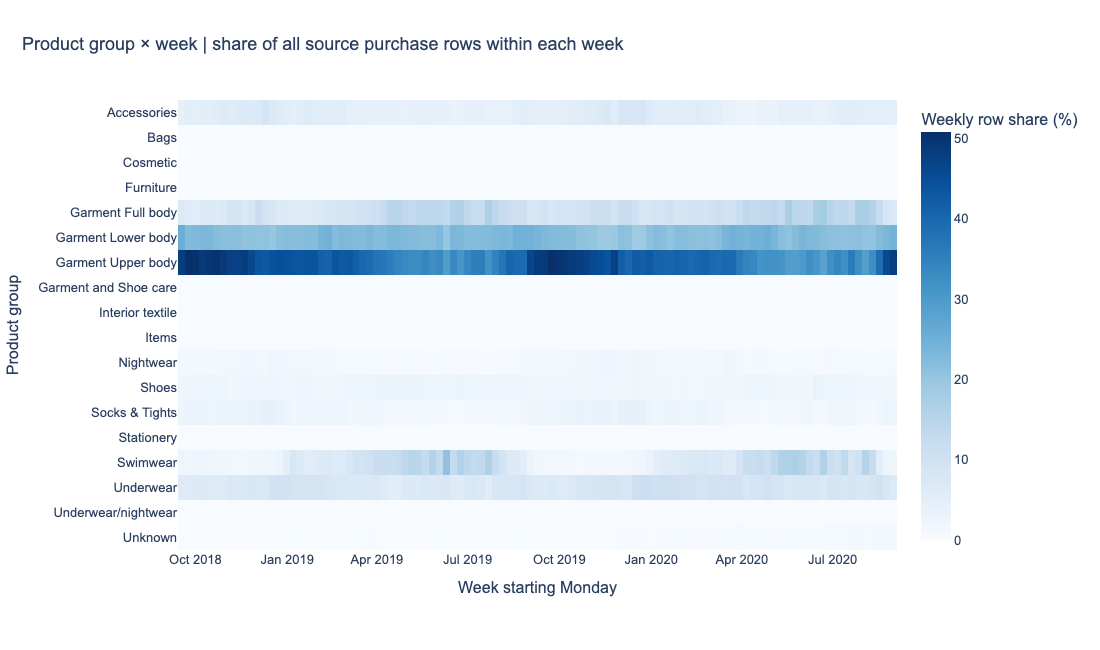

In [5]:
matrix = weekly_groups.pivot(index='product_group_name',columns='week',values='share_pct').fillna(0)
fig = px.imshow(matrix, aspect='auto', color_continuous_scale='Blues',
    labels={'x':'Week starting Monday','y':'Product group','color':'Weekly row share (%)'},
    title='Product group × week | share of all source purchase rows within each week')
show_figure(fig, PROJECT_ROOT, 'eda_category_week_heatmap', height=650)

**Interpretation and hypothesis.** Color represents a within-week transaction-row share. A structural zero means no retained purchase row for that combination; it is not evidence of a stockout. Compare category histories when designing affinity and popularity features.

## 6. Customer activity

**Question.** How unequal are observed customer histories?

,transaction_rows,distinct_articles,purchase_days,recency_days
count,1.345600e+06,1.345600e+06,1.345600e+06,1.345600e+06
mean,2.305894e+01,1.980775e+01,6.567034e+00,2.285506e+02
std,3.854933e+01,3.141551e+01,9.494871e+00,2.151846e+02
min,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
25%,3.000000e+00,3.000000e+00,1.000000e+00,4.600000e+01
50%,9.000000e+00,8.000000e+00,3.000000e+00,1.460000e+02
75%,2.700000e+01,2.300000e+01,8.000000e+00,3.900000e+02
90%,5.900000e+01,5.100000e+01,1.700000e+01,5.910000e+02
99%,1.840000e+02,1.510000e+02,4.400000e+01,7.040000e+02
max,1.863000e+03,1.325000e+03,4.090000e+02,7.130000e+02


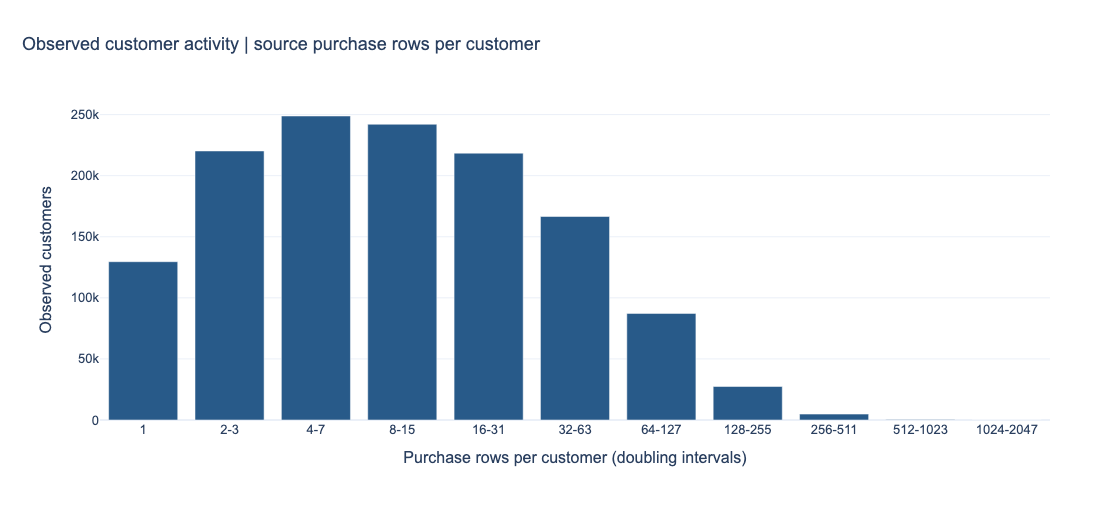

In [6]:
customer_activity = query("SELECT customer_id, count(*) transaction_rows, count(DISTINCT article_id) distinct_articles, count(DISTINCT t_dat) purchase_days, min(t_dat) first_purchase, max(t_dat) last_purchase FROM eda GROUP BY customer_id")
customer_activity['recency_days'] = (EDA_END_EXCLUSIVE-customer_activity['last_purchase']).dt.days
customer_activity['row_band'] = np.floor(np.log2(customer_activity['transaction_rows'])).astype(int)
activity_bands = customer_activity.groupby('row_band').size().rename('customers').reset_index()
activity_bands['row_range'] = activity_bands['row_band'].map(lambda b: str(2**b) if b==0 else f'{2**b}-{2**(b+1)-1}')
display(customer_activity[['transaction_rows','distinct_articles','purchase_days','recency_days']].describe(percentiles=[.25,.5,.75,.9,.99]))
fig = px.bar(activity_bands,x='row_range',y='customers',
    labels={'row_range':'Purchase rows per customer (doubling intervals)','customers':'Observed customers'},
    title='Observed customer activity | source purchase rows per customer')
show_figure(fig, PROJECT_ROOT, 'eda_customer_activity')

**Interpretation and hypothesis.** A customer with several rows can still have only one purchase date. The population excludes customers without any observed purchase in this interval. Activity, distinct articles and purchase days describe different aspects of history; assess model quality across history segments.

## 7. Customer recency

**Question.** How recently were observed customers active at the analytical cutoff?

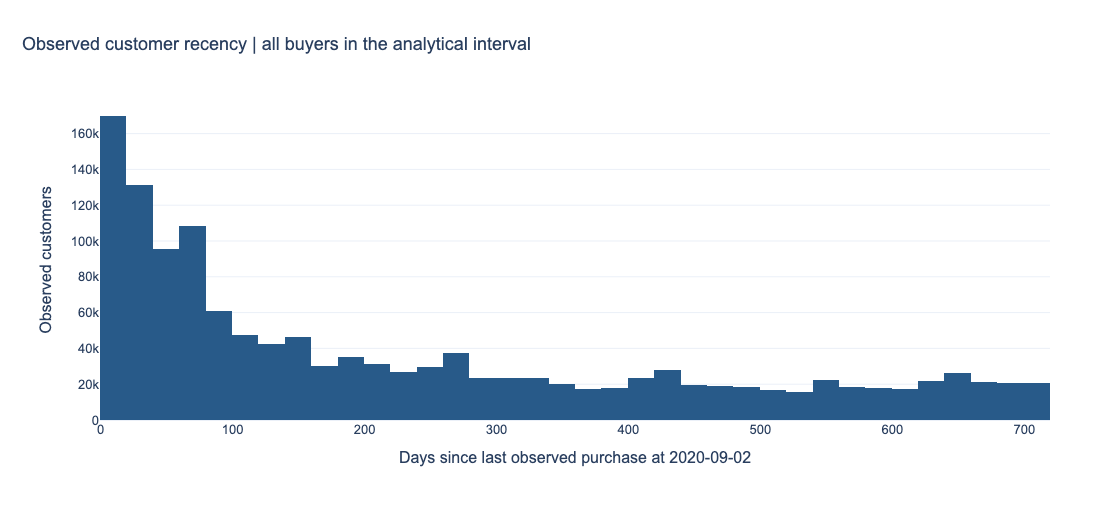

customers                    1345600.0
median_recency_days              146.0
customers_active_last_28d     234037.0
dtype: float64

In [7]:
fig = px.histogram(customer_activity, x='recency_days', nbins=40,
    labels={'recency_days':'Days since last observed purchase at 2020-09-02','count':'Observed customers'},
    title='Observed customer recency | all buyers in the analytical interval')
show_figure(fig, PROJECT_ROOT, 'eda_customer_recency')
display(pd.Series({'customers':len(customer_activity),'median_recency_days':customer_activity['recency_days'].median(),
    'customers_active_last_28d':int(customer_activity['recency_days'].le(28).sum())}))

**Interpretation and hypothesis.** Recency is measured from the exclusive cutoff: a purchase on 1 September has recency one day. A long interval since the last observed purchase does not establish churn. Missing history at a future cutoff requires an explicit indicator and fallback.

## 8. Repeated article purchases

**Question.** Do repeated rows reflect the same date or different purchase dates?

,pattern,customer_article_pairs,transaction_rows,pair_share_pct,row_share_pct
0,One row,23221271,23221271.0,87.123391,74.839451
1,"Multiple rows, one date",2322123,5028797.0,8.712324,16.207227
2,Multiple purchase dates,1109920,2778047.0,4.164285,8.953322


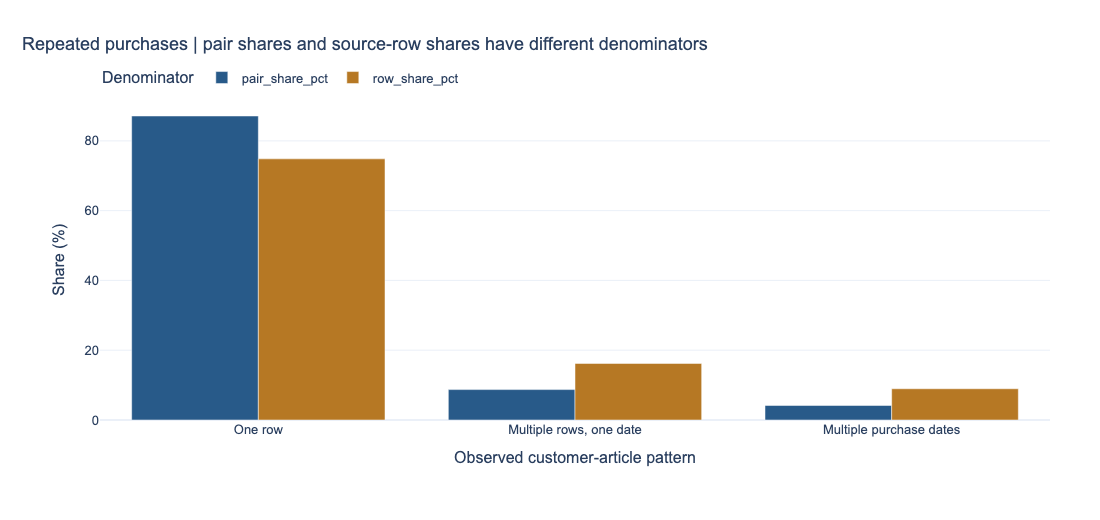

In [8]:
connection.sql('SELECT customer_id,article_id,count(*) AS rows,count(DISTINCT t_dat) purchase_days FROM eda GROUP BY customer_id,article_id').create_view('pair_history')
repeat_patterns = query("SELECT CASE WHEN rows=1 THEN 'One row' WHEN purchase_days=1 THEN 'Multiple rows, one date' ELSE 'Multiple purchase dates' END pattern,count(*) customer_article_pairs,sum(rows) transaction_rows FROM pair_history GROUP BY pattern")
repeat_patterns['pair_share_pct']=100*repeat_patterns['customer_article_pairs']/repeat_patterns['customer_article_pairs'].sum()
repeat_patterns['row_share_pct']=100*repeat_patterns['transaction_rows']/repeat_patterns['transaction_rows'].sum()
assert repeat_patterns['transaction_rows'].sum()==31_028_115
display(repeat_patterns)
fig=px.bar(repeat_patterns,x='pattern',y=['pair_share_pct','row_share_pct'],barmode='group',
    labels={'pattern':'Observed customer-article pattern','value':'Share (%)','variable':'Denominator'},
    title='Repeated purchases | pair shares and source-row shares have different denominators')
show_figure(fig, PROJECT_ROOT, 'eda_repeat_patterns')

**Interpretation and hypothesis.** Same-date repeated rows are retained without calling them separate orders. Multiple-date pairs support keeping previously purchased articles among candidates. Pair shares are not customer shares, and all rows of a repeated pair include its first observation.

## 9. Delay between repeated purchases

**Question.** How much time separates successive distinct purchase dates for the same customer and article?

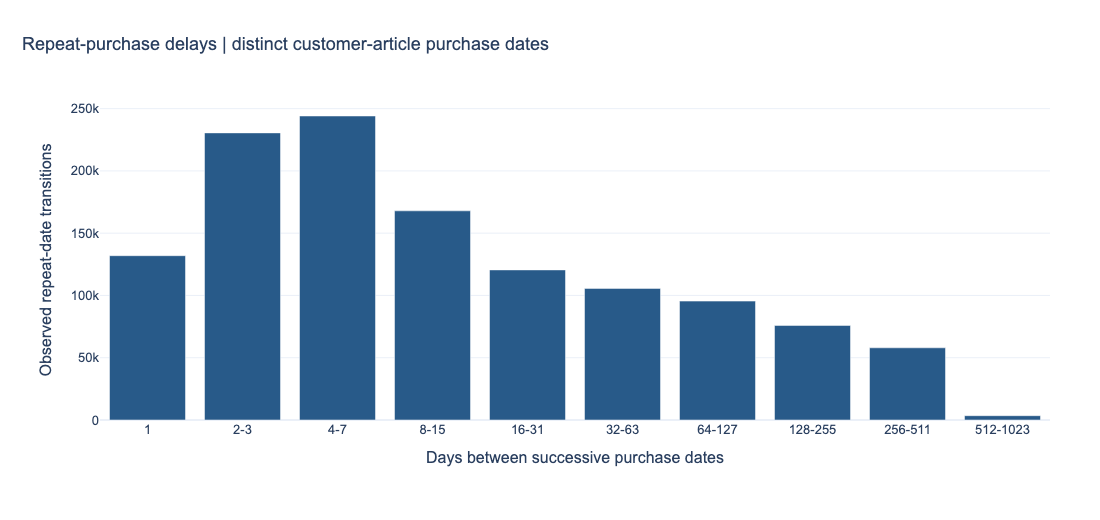

,activity_band,repeat_events,median_delay_days
0,1-10 rows,53972,5.0
1,11-50 rows,353763,7.0
2,51+ rows,825729,9.0


In [9]:
connection.sql('SELECT customer_id,article_id,t_dat,lag(t_dat) OVER(PARTITION BY customer_id,article_id ORDER BY t_dat) previous_date FROM (SELECT DISTINCT customer_id,article_id,t_dat FROM eda)').create_view('repeat_dates')
repeat_delays=query("SELECT date_diff('day',previous_date,t_dat) delay_days,count(*) repeat_events FROM repeat_dates WHERE previous_date IS NOT NULL GROUP BY delay_days ORDER BY delay_days")
assert repeat_delays['delay_days'].gt(0).all()
repeat_delays['delay_band']=np.floor(np.log2(repeat_delays['delay_days'])).astype(int)
delay_bands=repeat_delays.groupby('delay_band')['repeat_events'].sum().reset_index()
delay_bands['range']=delay_bands['delay_band'].map(lambda b: str(2**b) if b==0 else f'{2**b}-{2**(b+1)-1}')
fig=px.bar(delay_bands,x='range',y='repeat_events',labels={'range':'Days between successive purchase dates','repeat_events':'Observed repeat-date transitions'},
    title='Repeat-purchase delays | distinct customer-article purchase dates')
show_figure(fig, PROJECT_ROOT, 'eda_repeat_delays')
connection.register('_customer_activity',customer_activity[['customer_id','transaction_rows']])
repeat_by_activity=query("SELECT CASE WHEN a.transaction_rows<=10 THEN '1-10 rows' WHEN a.transaction_rows<=50 THEN '11-50 rows' ELSE '51+ rows' END activity_band,count(*) repeat_events,median(date_diff('day',r.previous_date,r.t_dat)) median_delay_days FROM repeat_dates r JOIN _customer_activity a USING(customer_id) WHERE r.previous_date IS NOT NULL GROUP BY activity_band")
display(repeat_by_activity)

**Interpretation and hypothesis.** The unit is one transition between distinct purchase dates, so repeated rows on one date do not create zero-day transitions. Longer histories expose more opportunities for repeats; the activity comparison is descriptive. Recency of a previous purchase is a plausible ranking feature.

## 10. Popularity concentration

**Question.** How many articles account for most source purchase rows?

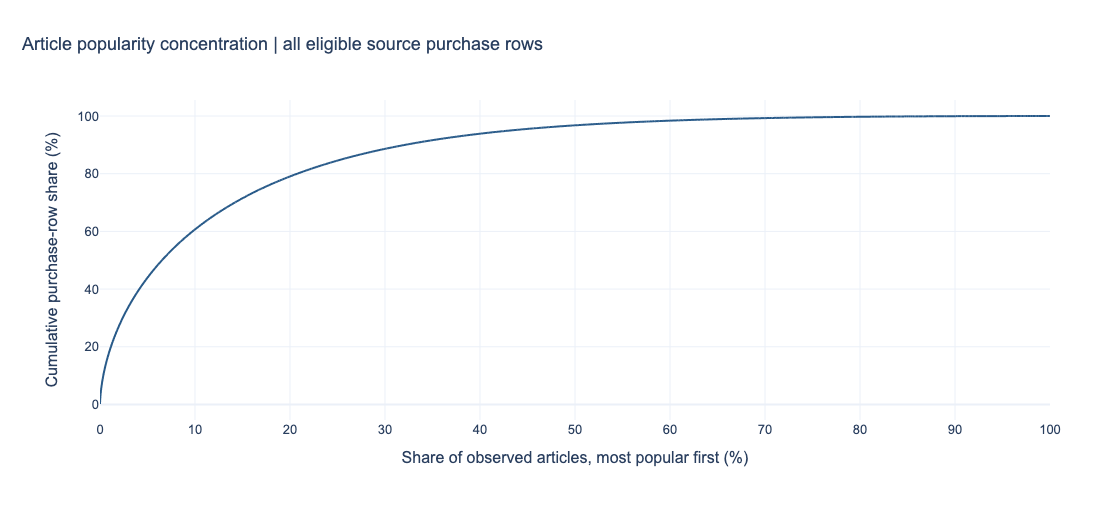

,article_id,transaction_rows,buyers,rank,article_share_pct,cumulative_row_share_pct
0,0706016001,48822,31457,1,0.000981,0.157348
1,0706016002,34298,24983,2,0.001962,0.267886
2,0372860001,30956,24993,3,0.002943,0.367654
3,0610776002,29497,22118,4,0.003924,0.462719
4,0759871002,26238,21543,5,0.004905,0.547281
5,0464297007,24838,18427,6,0.005886,0.627331
6,0372860002,23728,19491,7,0.006866,0.703804
7,0399223001,22102,15847,8,0.007847,0.775036
8,0610776001,22058,16583,9,0.008828,0.846126
9,0720125001,20868,17433,10,0.009809,0.913381


In [10]:
article_activity=query('SELECT article_id,count(*) transaction_rows,count(DISTINCT customer_id) buyers FROM eda GROUP BY article_id ORDER BY transaction_rows DESC,article_id')
article_activity['rank']=np.arange(1,len(article_activity)+1)
article_activity['article_share_pct']=100*article_activity['rank']/len(article_activity)
article_activity['cumulative_row_share_pct']=100*article_activity['transaction_rows'].cumsum()/article_activity['transaction_rows'].sum()
fig=px.line(article_activity,x='article_share_pct',y='cumulative_row_share_pct',
    labels={'article_share_pct':'Share of observed articles, most popular first (%)','cumulative_row_share_pct':'Cumulative purchase-row share (%)'},
    title='Article popularity concentration | all eligible source purchase rows')
show_figure(fig, PROJECT_ROOT, 'eda_popularity_concentration')
display(article_activity.head(20))

**Interpretation and hypothesis.** Concentration motivates a popularity baseline and bounded retrieval. It also creates a risk that recommendations cover only a narrow catalogue. Distinct buyers and purchase-row counts need not rank articles identically.

## 11. Renewal of top sellers

**Question.** How stable are weekly top-20 article lists?

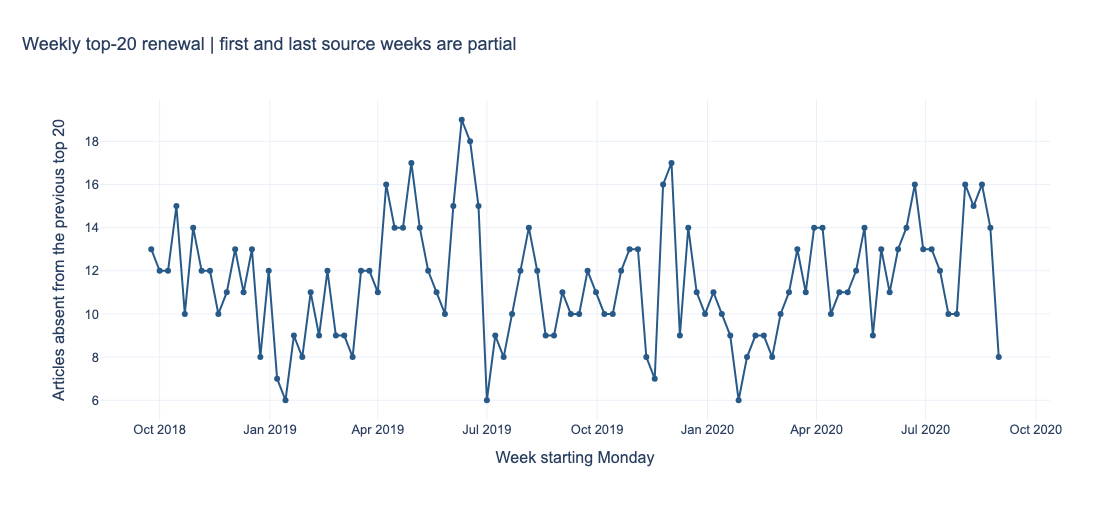

,week,new_articles,jaccard
count,102,102.000000,102.000000
mean,2019-09-12 12:00:00,11.500000,0.279114
min,2018-09-24 00:00:00,6.000000,0.025641
25%,2019-03-19 18:00:00,10.000000,0.212121
50%,2019-09-12 12:00:00,11.000000,0.290323
75%,2020-03-07 06:00:00,13.000000,0.333333
max,2020-08-31 00:00:00,19.000000,0.538462
std,NaN,2.713187,0.109392


In [11]:
weekly_top=query("SELECT week,article_id,transaction_rows FROM (SELECT date_trunc('week',t_dat) AS week,article_id,count(*) transaction_rows,row_number() OVER(PARTITION BY date_trunc('week',t_dat) ORDER BY count(*) DESC,article_id) popularity_rank FROM eda GROUP BY week,article_id) WHERE popularity_rank<=20 ORDER BY week,popularity_rank")
turnover=[];previous=None
for week,group in weekly_top.groupby('week',sort=True):
    current=set(group['article_id'])
    if previous is not None:turnover.append({'week':week,'new_articles':len(current-previous),'jaccard':len(current&previous)/len(current|previous)})
    previous=current
turnover=pd.DataFrame(turnover)
fig=px.line(turnover,x='week',y='new_articles',markers=True,
    labels={'week':'Week starting Monday','new_articles':'Articles absent from the previous top 20'},
    title='Weekly top-20 renewal | first and last source weeks are partial')
show_figure(fig, PROJECT_ROOT, 'eda_top_seller_turnover')
display(turnover.describe())

**Interpretation and hypothesis.** Ranking ties use article ID. New top-list membership measures list turnover, not a product launch. Boundary weeks have different exposure lengths. Changes motivate recent popularity and trend features; they do not prove an optimal lookback.

## 12. Category and colour breadth

**Question.** How many categories and colours occur in each observed customer history?

,product_groups,product_types,colours
count,1.345600e+06,1.345600e+06,1.345600e+06
mean,3.576549e+00,7.577230e+00,7.168315e+00
std,2.261787e+00,7.088633e+00,6.356830e+00
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,2.000000e+00,2.000000e+00,2.000000e+00
50%,3.000000e+00,5.000000e+00,5.000000e+00
75%,5.000000e+00,1.100000e+01,1.000000e+01
max,1.300000e+01,6.500000e+01,4.500000e+01


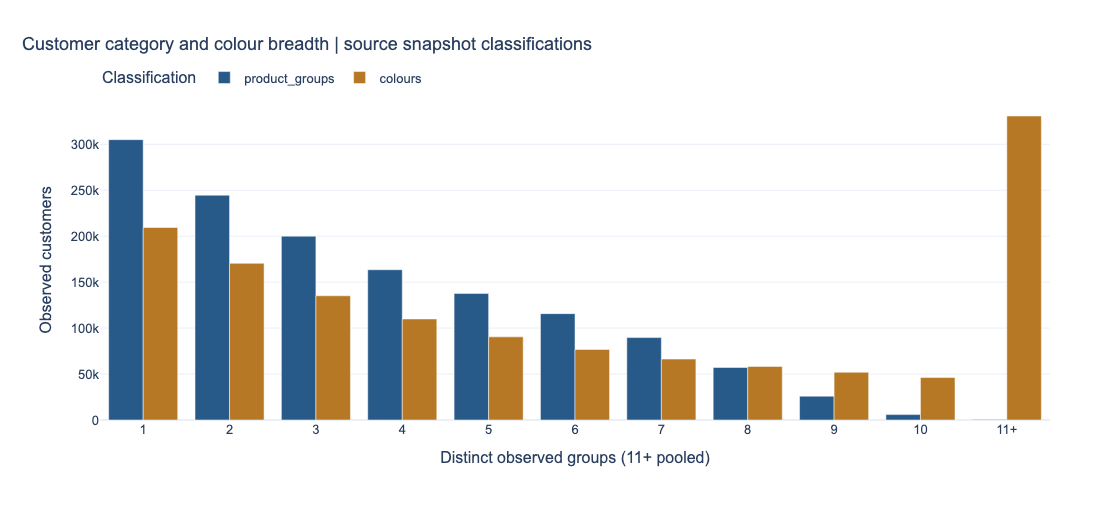

In [12]:
breadth=query('SELECT customer_id,count(DISTINCT product_group_name) product_groups,count(DISTINCT product_type_name) product_types,count(DISTINCT colour_group_name) colours FROM eda_joined GROUP BY customer_id')
display(breadth[['product_groups','product_types','colours']].describe())
breadth_counts=[]
for column in ['product_groups','colours']:
    values=breadth[column].clip(upper=11).value_counts().sort_index()
    breadth_counts.extend({'measure':column,'breadth':str(n) if n<11 else '11+','customers':int(v)} for n,v in values.items())
fig=px.bar(pd.DataFrame(breadth_counts),x='breadth',y='customers',color='measure',barmode='group',
    category_orders={'breadth':[str(n) for n in range(1,11)]+['11+']},
    labels={'breadth':'Distinct observed groups (11+ pooled)','customers':'Observed customers','measure':'Classification'},
    title='Customer category and colour breadth | source snapshot classifications')
show_figure(fig, PROJECT_ROOT, 'eda_category_colour_breadth')

**Interpretation and hypothesis.** Breadth depends on observed activity and classification granularity. A product type is finer than a broad product group. Diversity counts motivate customer features; they do not establish the diversity a customer wants in a recommendation list.

## 13. Category-colour affinity matrix

**Question.** How does the observed colour mix differ across product groups?

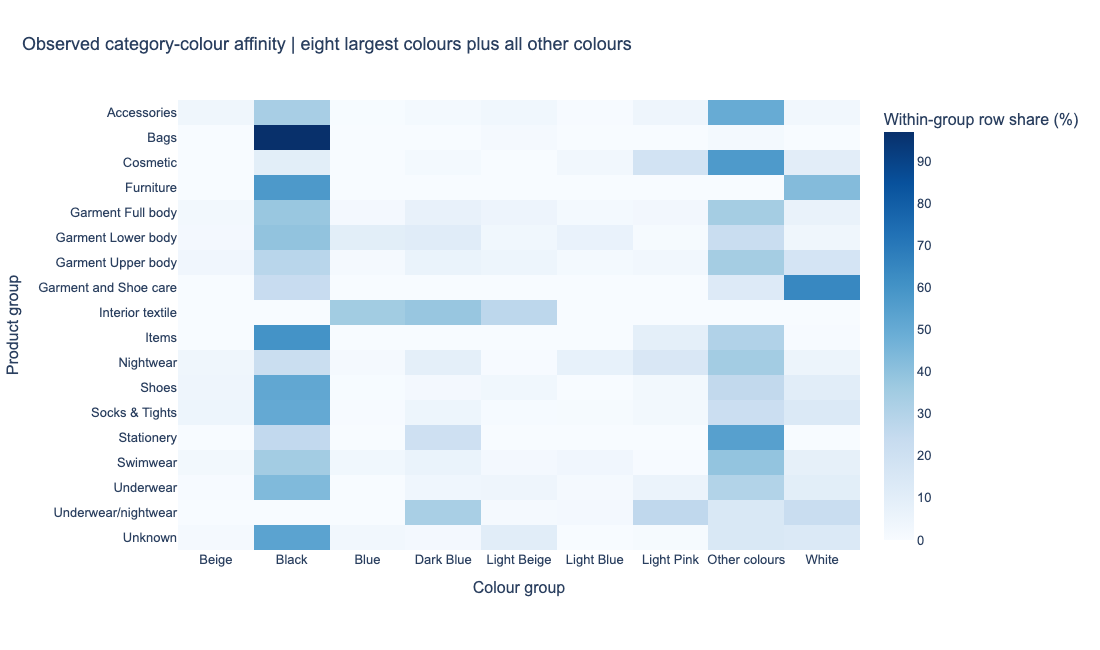

In [13]:
affinity=query('SELECT product_group_name,colour_group_name,count(*) transaction_rows FROM eda_joined GROUP BY ALL')
top_colours=affinity.groupby('colour_group_name')['transaction_rows'].sum().nlargest(8).index
affinity['display_colour']=affinity['colour_group_name'].where(affinity['colour_group_name'].isin(top_colours),'Other colours')
affinity=affinity.groupby(['product_group_name','display_colour'])['transaction_rows'].sum().reset_index()
affinity['within_group_share_pct']=100*affinity['transaction_rows']/affinity.groupby('product_group_name')['transaction_rows'].transform('sum')
assert np.allclose(affinity.groupby('product_group_name')['within_group_share_pct'].sum(),100)
affinity_matrix=affinity.pivot(index='product_group_name',columns='display_colour',values='within_group_share_pct').fillna(0)
fig=px.imshow(affinity_matrix,aspect='auto',color_continuous_scale='Blues',
    labels={'x':'Colour group','y':'Product group','color':'Within-group row share (%)'},
    title='Observed category-colour affinity | eight largest colours plus all other colours')
show_figure(fig, PROJECT_ROOT, 'eda_colour_affinity',height=650)

**Interpretation and hypothesis.** Each product-group row sums to 100%; the denominator is its purchase-row count. This aggregate matrix describes category-colour associations, while personal colour affinity is computed separately from each customer's past purchases. Neither is a causal preference estimate.

## 14. Prices by category

**Question.** How do observed price distributions differ across broad product groups?

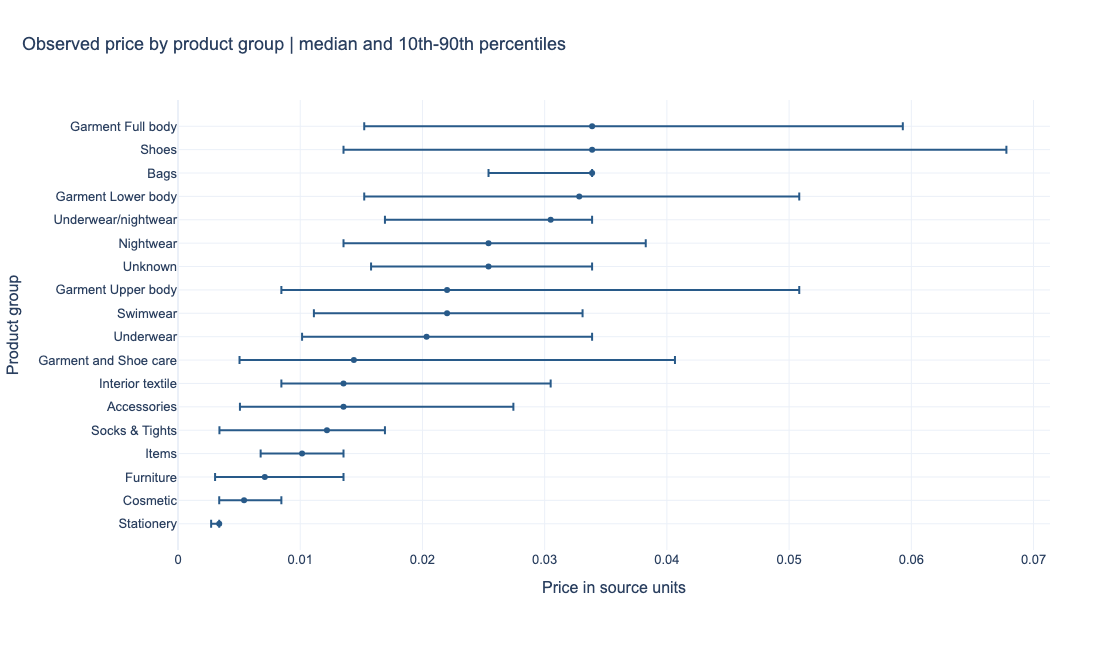

,product_group_name,transaction_rows,p10,median,p90
0,Stationery,221,0.002712,0.003373,0.003373
1,Cosmetic,1488,0.003373,0.005407,0.008458
2,Furniture,533,0.003034,0.007102,0.013542
3,Items,4825,0.006763,0.010153,0.013542
4,Socks & Tights,666288,0.003390,0.012186,0.016932
5,Accessories,1562774,0.005068,0.013542,0.027441
6,Interior textile,74,0.008458,0.013542,0.030492
7,Garment and Shoe care,272,0.005034,0.014390,0.040661
8,Underwear,2509832,0.010153,0.020339,0.033881
9,Swimwear,2567236,0.011119,0.022017,0.033102


In [14]:
price_groups=query('SELECT product_group_name,count(*) transaction_rows,quantile_cont(price,.1) p10,quantile_cont(price,.5) median,quantile_cont(price,.9) p90 FROM eda_joined GROUP BY product_group_name ORDER BY median')
fig=go.Figure(go.Scatter(x=price_groups['median'],y=price_groups['product_group_name'],mode='markers',
    error_x={'type':'data','symmetric':False,'array':price_groups['p90']-price_groups['median'],'arrayminus':price_groups['median']-price_groups['p10']}))
fig.update_layout(title='Observed price by product group | median and 10th-90th percentiles',
    xaxis_title='Price in source units',yaxis_title='Product group',xaxis_rangemode='tozero')
show_figure(fig, PROJECT_ROOT, 'eda_price_by_category',height=650)
display(price_groups)

**Interpretation and hypothesis.** Intervals describe the observed price spread; they are not confidence intervals. Source prices have no justified euro conversion here. Historical price features would require cutoff-specific observations; this EDA does not make a future transaction price an available model input.

## 15. Price history

**Question.** How do weekly source price summaries evolve?

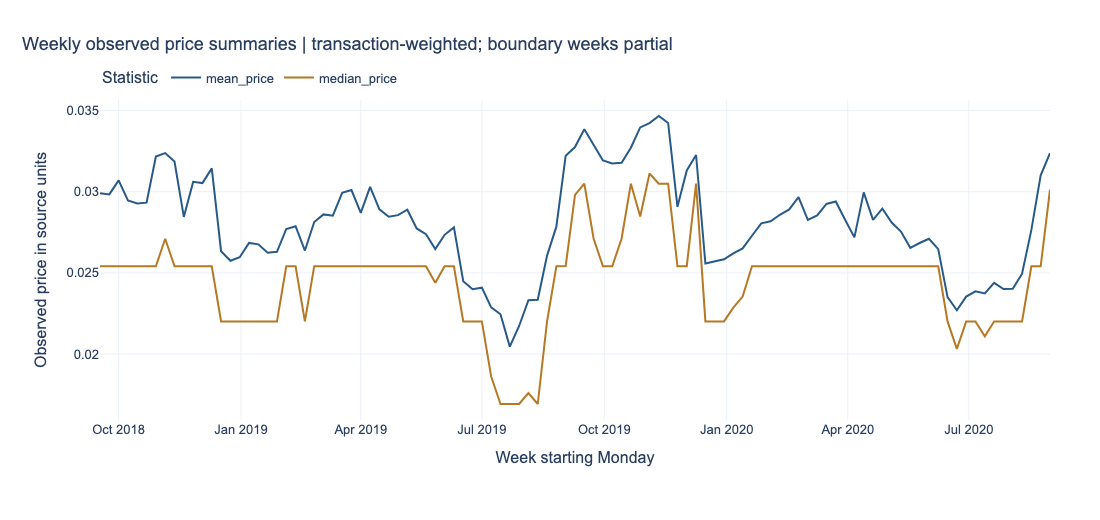

In [15]:
weekly_prices=query("SELECT date_trunc('week',t_dat) AS week,count(*) transaction_rows,avg(price) mean_price,median(price) median_price FROM eda GROUP BY week ORDER BY week")
fig=px.line(weekly_prices,x='week',y=['mean_price','median_price'],
    labels={'week':'Week starting Monday','value':'Observed price in source units','variable':'Statistic'},
    title='Weekly observed price summaries | transaction-weighted; boundary weeks partial')
show_figure(fig, PROJECT_ROOT, 'eda_weekly_price')

**Interpretation and hypothesis.** A change in aggregate prices can reflect a different product mix, not a price change for identical articles. This plot supplies context and does not establish a commercial mechanism.

## 16. Channel and category

**Question.** How are source channel codes distributed within product groups?

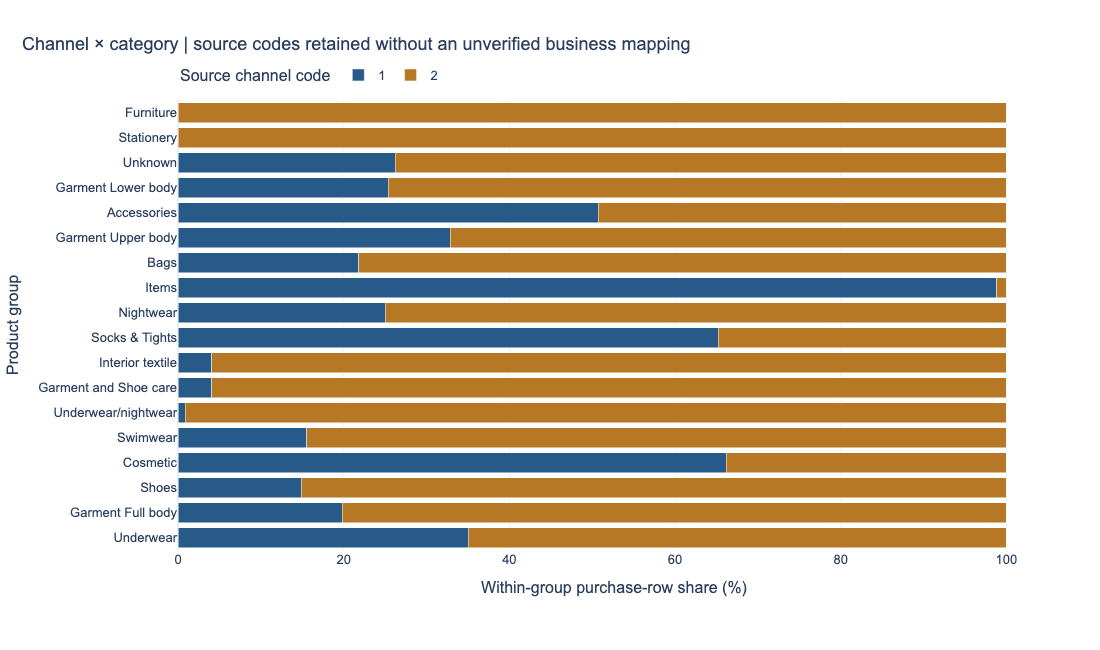

,product_group_name,sales_channel_id,transaction_rows,share_pct,channel_code
0,Underwear,1,879227,35.031309,1
1,Socks & Tights,2,231883,34.802218,2
2,Garment Full body,1,692561,19.829053,1
3,Shoes,1,108750,14.849234,1
4,Nightwear,2,253982,74.973802,2
5,Cosmetic,1,985,66.196237,1
6,Bags,2,5363,78.200642,2
7,Items,2,57,1.181347,2
8,Stationery,2,221,100.000000,2
9,Garment Lower body,2,5124971,74.604912,2


In [16]:
channel_groups=query('SELECT product_group_name,sales_channel_id,count(*) transaction_rows FROM eda_joined GROUP BY ALL')
channel_groups['share_pct']=100*channel_groups['transaction_rows']/channel_groups.groupby('product_group_name')['transaction_rows'].transform('sum')
channel_groups['channel_code']=channel_groups['sales_channel_id'].astype(str)
assert np.allclose(channel_groups.groupby('product_group_name')['share_pct'].sum(),100)
fig=px.bar(channel_groups,y='product_group_name',x='share_pct',color='channel_code',orientation='h',barmode='stack',
    labels={'product_group_name':'Product group','share_pct':'Within-group purchase-row share (%)','channel_code':'Source channel code'},
    title='Channel × category | source codes retained without an unverified business mapping')
show_figure(fig, PROJECT_ROOT, 'eda_channel_category',height=650)
display(channel_groups)

**Interpretation and hypothesis.** The denominator is all eligible purchase rows in each product group. Codes are not renamed as online or store without evidence. A customer's historical channel share can be computed without using their next purchase channel.

## 17. Hypotheses and modelling consequences

| Hypothesis | Evidence examined | Next controlled comparison |
|---|---|---|
| Recent activity adds information | Daily activity and weekly top-seller renewal | 7-day popularity baseline and 7/28-day article features |
| Category affinity helps retrieval | Weekly composition and observed breadth | Popularity within three preferred product types |
| Previous purchases remain useful | Repeated pairs and repeat-date delays | Recent-purchase baseline and personal-history candidates |
| History richness affects performance | Activity, purchase days and recency | Customer-history and activity segments on validation |
| Colour and context add ranking information | Colour matrix, breadth and channel-category mix | Numeric affinity/context features, followed by declared ablations |

These are testable hypotheses, not established predictive gains. Keep the candidate budget fixed for feature ablations and preserve all future targets in evaluation. The next notebook establishes the three reference methods before fitting a learned ranker.

In [17]:
eda_summary={
    'start_inclusive':'2018-09-20','end_exclusive':str(EDA_END_EXCLUSIVE.date()),
    'transaction_rows':int(scope.loc[0,'transaction_rows']),'customers':int(scope.loc[0,'customers']),
    'articles':int(scope.loc[0,'articles']),'calendar_days':len(daily),
    'customer_article_pairs':int(repeat_patterns['customer_article_pairs'].sum()),
    'median_customer_distinct_articles':float(customer_activity['distinct_articles'].median()),
    'median_customer_recency_days':float(customer_activity['recency_days'].median()),
    'repeat_date_transitions':int(repeat_delays['repeat_events'].sum()),
    'median_weekly_top20_new_articles':float(turnover['new_articles'].median()),
    'top_1pct_article_row_share_pct':float(article_activity.iloc[int(np.ceil(len(article_activity)*.01))-1]['cumulative_row_share_pct']),
    'product_groups':int(weekly_groups['product_group_name'].nunique()),
    'figures':'artifacts/figures/eda_*.png'}
output=PROJECT_ROOT/'data/processed/weekly_v1/eda';output.mkdir(parents=True,exist_ok=True)
(output/'summary.json').write_text(json.dumps(eda_summary,indent=2)+'\n')
for name,frame in [('scope',scope),('repeat_patterns',repeat_patterns),('repeat_delays',repeat_delays),('repeat_by_activity',repeat_by_activity),('weekly_turnover',turnover),('price_groups',price_groups),('channel_groups',channel_groups),('weekly_groups',weekly_groups)]:
    frame.to_csv(output/f'{name}.csv',index=False)
connection.close()
display(pd.Series(eda_summary))

start_inclusive                                       2018-09-20
end_exclusive                                         2020-09-02
transaction_rows                                        31028115
customers                                                1345600
articles                                                  101945
calendar_days                                                713
customer_article_pairs                                  26653314
median_customer_distinct_articles                            8.0
median_customer_recency_days                               146.0
repeat_date_transitions                                  1233464
median_weekly_top20_new_articles                            11.0
top_1pct_article_row_share_pct                          18.49074
product_groups                                                18
figures                              artifacts/figures/eda_*.png
dtype: object